# Activation probes from scratch: a generic pattern, then RAG faithfulness

**Goal.** Understand what an activation probe is by building one end to end, with nothing hidden in a library. The notebook has two halves that share one codebase:

1. **A generic pattern** (Sections 1 and 2). Task-agnostic functions: describe an example, run a frozen language model, pull out its internal activations, fit a small classifier on them, evaluate it properly. To probe for a different concept you only write one function that builds examples (Section 5 shows this in 10 lines).
2. **A specific instance** (Sections 3 and 4). RAG faithfulness: given a retrieved passage, a question and an answer, is the answer supported by the passage? We use the open HaluBench dataset from Hugging Face and a 0.5B-parameter model that runs on a Mac.

**Map of the notebook**

| Section | What it does |
|---|---|
| 0 | Setup: installs, device, config |
| 1 | Concepts and maths, no code |
| 2 | Generic toolkit: examples, model, hooks, extraction, probes, metrics, splits |
| 3 | Faithfulness: data, extraction, layer sweep, test result, baselines and controls, generalisation, which token to read |
| 4 | Swaps: methods from recent papers that can replace the baseline, three of them implemented |
| 5 | Adapt to your own task: template plus a tiny second task |
| 6 | What a probe result means, what it does not, and a reading list |

**Conventions used everywhere**

- $N$ = number of examples, $T$ = number of tokens in one example, $L$ = number of transformer blocks, $d$ = width of the model (size of one activation vector).
- Label $y = 1$ means the **positive class**. For faithfulness, $y = 1$ means **unfaithful** (the answer is not supported by the passage), because that is the thing we want to detect.
- Every array's shape is written in a comment next to the line that creates it.

Runtime with the default config: a few minutes on an Apple Silicon Mac (MPS), about 30 minutes on a 2-core CPU. Activations are cached on disk, so only the first run is slow.

## 0. Setup

In [1]:
# Uncomment on first use. Everything here is CPU/MPS friendly; no GPU-only packages.
# %pip install -q torch transformers datasets scikit-learn matplotlib pandas tqdm scipy

In [2]:
import hashlib
import html
import os
import pickle
import re
from dataclasses import dataclass, field

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from scipy.stats import rankdata
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm

pd.set_option("display.width", 160)
pd.set_option("display.precision", 3)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
@dataclass
class Config:
    """Every knob in one place. Change a value here and rerun from the top."""

    # A Hugging Face model id OR a local folder with HF-format weights (config.json + *.safetensors).
    # The default is the model every number in this notebook was produced with.
    # Others (see the table in Section 2.2): "Qwen/Qwen3.5-0.8B", "google/gemma-4-E2B-it",
    # "microsoft/Phi-4-mini-instruct", "microsoft/Phi-4-mini-reasoning".
    model_name: str = "Qwen/Qwen2.5-0.5B-Instruct"
    dtype: str = "float32"             # "float16" halves memory; use it for 3B+ models on MPS

    # Data size. Examples longer than max_tokens are dropped (not truncated, see Section 3.2).
    max_tokens: int = 512
    n_per_source_label: int = 100      # examples per (source dataset, label) cell

    # Probe settings.
    probe_C: float = 0.01              # inverse L2 strength for logistic regression (Section 1.4)
    split_fractions: tuple = (0.6, 0.2, 0.2)   # train, validation, test

    # Layer whose per-token activations we keep for Section 4.3. None = middle layer.
    token_layer: int | None = None

    seed: int = 0
    cache_dir: str = "probe_cache"


cfg = Config()


def pick_device() -> torch.device:
    """Apple Silicon GPU (MPS) if present, else CUDA, else CPU."""
    if torch.backends.mps.is_available():
        return torch.device("mps")
    if torch.cuda.is_available():
        return torch.device("cuda")
    return torch.device("cpu")


device = pick_device()
torch.manual_seed(cfg.seed)
np.random.seed(cfg.seed)
os.makedirs(cfg.cache_dir, exist_ok=True)
print("device:", device)

device: cpu


## 1. Concepts and maths

Read this once, then come back to it as each piece appears in code.

### 1.1 What an "activation" is

A decoder-only transformer turns a token sequence $x_1, \dots, x_T$ into one vector per token per layer. Write $h^{(\ell)}_t \in \mathbb{R}^d$ for the vector at layer $\ell$ and token position $t$. The sequence of these vectors across layers is called the **residual stream**, because each block *adds* to it:

$$
h^{(0)}_t = \mathrm{Embed}(x_t), \qquad
h^{(\ell)}_t = h^{(\ell-1)}_t + \mathrm{Attn}^{(\ell)}\big(h^{(\ell-1)}_{1:t}\big)_t + \mathrm{MLP}^{(\ell)}\big(\cdot\big)_t, \quad \ell = 1, \dots, L .
$$

Two facts matter for everything below:

- **Shapes.** Hugging Face returns `hidden_states`, a tuple of $L+1$ tensors, each of shape $(\text{batch}, T, d)$. Index 0 is the embedding output, index $\ell$ is the output of block $\ell$.
- **Causality.** Attention in a decoder only looks left: $h^{(\ell)}_t$ is a function of $x_1, \dots, x_t$ and nothing after. So the vector at an *answer* token can contain information about the *passage* that came before it, but a passage token's vector knows nothing about the answer. This decides where we read from.

"Activation" in this notebook always means a residual-stream vector $h^{(\ell)}_t$. (You can also probe attention outputs, MLP outputs or attention patterns; Section 4 points to papers that do.)

### 1.2 The probing problem

We have a labelled dataset $\mathcal{D} = \{(x_i, y_i)\}_{i=1}^N$ with $y_i \in \{0, 1\}$ and a **frozen** language model $f$. Probing asks: *can a simple function read $y$ off the model's activations?*

1. Run $f$ on $x_i$ and collect $h^{(\ell)}_{t}$ for all tokens $t$.
2. **Pool** the per-token vectors into one feature vector $z_i = \phi_\ell(x_i) \in \mathbb{R}^d$ (Section 1.3).
3. Fit a small classifier $g_\theta : \mathbb{R}^d \to \mathbb{R}$, the **probe**, on $\{(z_i, y_i)\}$. Only $\theta$ is trained. The language model never changes.
4. Measure how well $g_\theta(z)$ predicts $y$ on examples it has not seen.

If a *linear* $g_\theta$ works, the concept is **linearly decodable** at layer $\ell$: there is a direction in activation space along which the two classes separate.

### 1.3 Pooling: from $T$ vectors to one

Sequences have different lengths, the probe wants one vector. Let $S \subseteq \{1,\dots,T\}$ be a chosen set of token positions (the **span**).

- **Last token:** $z = h^{(\ell)}_T$. One vector that, by causality, has seen everything. Good when the prompt ends at a point where the model must "decide" something.
- **Mean over a span:** $z = \frac{1}{|S|}\sum_{t \in S} h^{(\ell)}_t$. Averages out per-token noise. If the evidence sits in a few tokens of a long span, the mean dilutes it.
- **Learned pooling** (attention, max): Section 4.3.

For faithfulness we take $S$ = the answer tokens, because those are the positions that have read both the passage and the claim being checked.

### 1.4 The baseline probe: logistic regression

First standardise each feature using training-set statistics, $\tilde z_j = (z_j - \mu_j)/\sigma_j$, so that all $d$ coordinates are on the same scale and one regularisation strength is meaningful for all of them. Then

$$
s(z) = w^\top \tilde z + b, \qquad p(y = 1 \mid z) = \sigma\big(s(z)\big) = \frac{1}{1 + e^{-s(z)}} .
$$

$s$ is the **score** (a logit). $w \in \mathbb{R}^d$ is the **probe direction**. Geometrically, $s$ is the signed distance of $\tilde z$ from the hyperplane $\{ \tilde z : w^\top \tilde z + b = 0\}$, scaled by $\lVert w \rVert$.

We fit $w, b$ by minimising the mean cross-entropy plus an L2 penalty:

$$
\mathcal{L}(w, b) = -\frac{1}{N}\sum_{i=1}^{N}\Big[y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big] + \frac{\lambda}{2}\lVert w\rVert_2^2 , \qquad p_i = \sigma(w^\top \tilde z_i + b).
$$

The gradients are short enough to implement by hand (we do, in Section 2.6):

$$
\nabla_w \mathcal{L} = \frac{1}{N}\tilde Z^\top (p - y) + \lambda w, \qquad \nabla_b \mathcal{L} = \frac{1}{N}\sum_i (p_i - y_i),
$$

where $\tilde Z \in \mathbb{R}^{N \times d}$ stacks the standardised features. scikit-learn parametrises the same problem with $C$, where $\lambda = 1/(C N)$: **small $C$ means strong regularisation**.

Why the penalty is not optional: here $d = 896$ and we train on a few hundred examples, so $d > N$. Without regularisation a linear model can fit *any* labels on the training set, including random ones (Section 3.8 demonstrates this). Held-out data and regularisation are what make the number mean something.

### 1.5 An even simpler probe: difference of means

Let $\mu_1, \mu_0$ be the mean feature vectors of the two classes. Take

$$
w_{\text{dm}} = \mu_1 - \mu_0, \qquad s(z) = w_{\text{dm}}^\top\Big(z - \tfrac{1}{2}(\mu_1 + \mu_0)\Big).
$$

No optimisation, no hyperparameters. If the classes are Gaussian with a shared covariance $\Sigma$, the optimal linear direction is $w_{\text{LDA}} = \Sigma^{-1}(\mu_1 - \mu_0)$ (linear discriminant analysis); difference of means is the special case that ignores $\Sigma$. Marks and Tegmark (2023) call this the mass-mean probe and argue its direction is more causally relevant than the logistic regression direction. We compare all three in Section 4.1.

### 1.6 How we score a probe

A probe outputs a real number $s$ per example. We need threshold-free and threshold-specific views:

- **AUROC**: the probability that a random positive scores higher than a random negative, $\mathrm{AUROC} = P\big(s(z^+) > s(z^-)\big)$. 0.5 is chance, 1.0 is perfect. It ignores calibration and class balance.
- **TPR at a fixed FPR** (for example 5%): choose the threshold that flags 5% of the faithful answers by mistake, then report the share of unfaithful answers caught. This is what a deployed detector cares about.
- **Bootstrap confidence interval**: resample the test set with replacement many times and recompute the metric. With a test set of about 200, AUROC moves by several points from sampling alone, so every headline number comes with an interval.

### 1.7 The four ways a probe result misleads you

1. **Overfitting and selection leakage.** $d > N$, and we also choose a layer, a pooling and $C$. Each choice made on the test set inflates the result. Fix: three splits. Fit on *train*, choose on *validation*, report on *test* once.
2. **Shortcuts in the data.** The probe finds *any* feature that predicts the label. If unfaithful answers are longer, a probe can "detect hallucination" by measuring length. Fix: baselines that only see the shortcut (Section 3.7).
3. **The probe did the work, not the model.** A flexible probe can learn the task from the inputs. Fix: keep the probe simple and compare against the same probe on a representation that cannot contain the answer (our "closed-book" control in Section 3.7; control tasks in Hewitt and Liang, 2019).
4. **Decodable is not used.** A probe shows information is *present* in the activations. It does not show the model *uses* it (Belinkov, 2022). That takes interventions (steering, ablation), which are out of scope here.

## 2. The generic toolkit

Nothing in this section knows about faithfulness. Each subsection adds one reusable piece.

### 2.1 One schema for every probing task

Any sequence-level probing task can be written as: *some text the model reads first* (`context`), *the span we care about* (`target`), *optional text after it* (`suffix`), and a label. The model reads `context + target + suffix`; mean pooling runs over the `target` tokens only.

In [4]:
@dataclass
class ProbeExample:
    """One labelled example for a sequence-level probe.

    context   : text before the span. The model reads it; we do not pool over it.
    target    : the span whose token activations are mean-pooled.
    label     : 1 = positive class (the thing to detect), 0 = negative class.
    suffix    : optional text after the span. "Last token" pooling reads the final suffix token.
    group     : a name used only for reporting and for generalisation tests (e.g. source dataset).
    split_key : rows sharing a split_key always land in the same split (e.g. same passage).
                Empty string means "this row is its own unit".
    """

    context: str
    target: str
    label: int
    suffix: str = ""
    group: str = "all"
    split_key: str = ""

    @property
    def text(self) -> str:
        return self.context + self.target + self.suffix

### 2.2 Load a frozen model

`eval()` switches off dropout. We never call `backward()` on the language model, and every forward pass runs under `torch.no_grad()`.

In [5]:
from transformers import AutoModelForCausalLM, AutoTokenizer


def load_model(model_name: str, device: torch.device, dtype: str = "float32"):
    """Returns (tokenizer, model). model_name is a Hugging Face id or a local folder."""
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForCausalLM.from_pretrained(model_name).to(getattr(torch, dtype)).to(device).eval()
    for p in model.parameters():
        p.requires_grad_(False)          # frozen: the probe is the only thing we train
    return tok, model


@torch.no_grad()
def model_dims(model, tok, device):
    """(L, d) measured from a real forward pass, so it works whatever the config layout is."""
    hs = model(**tok("hello", return_tensors="pt").to(device), output_hidden_states=True).hidden_states
    return len(hs) - 1, hs[0].shape[-1]


tok, model = load_model(cfg.model_name, device, cfg.dtype)
N_LAYERS, D_MODEL = model_dims(model, tok, device)     # L, d
TOKEN_LAYER = cfg.token_layer if cfg.token_layer is not None else N_LAYERS // 2
print(f"L = {N_LAYERS} blocks, d = {D_MODEL}, token-level layer = {TOKEN_LAYER}")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:  45%|████▍     | 130/290 [00:00<00:00, 1251.10it/s]

Loading weights:  88%|████████▊ | 256/290 [00:00<00:00, 755.38it/s] 

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 812.40it/s]

L = 24 blocks, d = 896, token-level layer = 12


**Using other models, including ones you already have locally.** Set `cfg.model_name` to the Hugging Face id or to the folder path. The folder must be in Hugging Face Transformers format (`config.json` plus `.safetensors`). GGUF files (Ollama, LM Studio, llama.cpp) and MLX conversions cannot be loaded here, because we need PyTorch modules to read activations from.

| Model | `model_name` | Status with this notebook | Notes |
|---|---|---|---|
| Qwen2.5-0.5B-Instruct | `Qwen/Qwen2.5-0.5B-Instruct` | Full run; all numbers below | $L = 24$, $d = 896$ |
| Qwen3.5-0.8B | `Qwen/Qwen3.5-0.8B` | Small end-to-end run (80 examples) completed without errors; its numbers are not reported here | $L = 24$, $d = 1024$. 18 of its 24 blocks use Gated DeltaNet (a linear, recurrent form of attention) and only 6 use softmax attention. Residual-stream probing is unaffected and causality still holds, but attention-map methods such as Lookback Lens only have those 6 layers to work with. Transformers prints a notice that it falls back to slower reference kernels unless `flash-linear-attention` and `causal_conv1d` are installed; results are the same. |
| Gemma 4 E2B | `google/gemma-4-E2B-it` | Not tested | Multimodal model; its model card loads it with `AutoModelForCausalLM`, which is what `load_model` uses. Set `dtype="float16"`: the stored parameter count is far above 2B because of its per-layer embedding tables. Check that the hook cell in Section 2.3 prints a difference of about 0 before trusting anything else. |
| Phi-4-mini, instruct and reasoning | `microsoft/Phi-4-mini-instruct`, `microsoft/Phi-4-mini-reasoning` | Not tested | About 3.8B parameters, so set `dtype="float16"`. Wider activations mean the cached arrays are several times larger. The pair is a ready-made experiment: same architecture, different fine-tuning, so any difference in the layer curves comes from training, not from architecture. We only *read* text with the model, so no thinking tokens are generated for the reasoning variant. |

If you change model, every number and every chosen layer changes. Rerun from the top; the cache is keyed by model so nothing stale is reused.

### 2.3 Finding the span, and seeing the activations

The tokenizer can return, for each token, the character range it covers (`offset_mapping`). A token belongs to the target span if its character range lies inside the target's character range.

One subtlety decides the exact rule. Tokenizers merge characters across our boundaries: with the default model's tokenizer the final `.` of an answer and the `\n\n` that follows it become the single token `.\n\n`. That token is half answer, half suffix. We exclude such straddling tokens so that the span contains answer text only.

In [6]:
def tokenize_with_span(tok, ex: ProbeExample):
    """Tokenise ex.text and mark which tokens belong to ex.target.

    Returns
      enc  : dict with input_ids and attention_mask, each of shape [1, T]
      span : bool tensor of shape [T], True on target tokens
    """
    enc = tok(ex.text, return_offsets_mapping=True, return_tensors="pt")
    offsets = enc.pop("offset_mapping")[0]                  # [T, 2] (char_start, char_end) per token
    start = len(ex.context)
    end = start + len(ex.target)
    span = (offsets[:, 0] >= start) & (offsets[:, 1] <= end) & (offsets[:, 1] > offsets[:, 0])   # fully inside
    if not span.any():                                      # e.g. a one-character target merged into a neighbour
        span = (offsets[:, 1] > start) & (offsets[:, 0] < end)   # fall back to "overlaps"
    assert span.any(), f"empty target span for: {ex.target!r}"
    return enc, span


demo = ProbeExample(
    context="Passage:\nThe Eiffel Tower is in Paris.\n\nQuestion: Where is the Eiffel Tower?\n\nAnswer:",
    target=" It is in Rome.",
    label=1,
)
enc, span = tokenize_with_span(tok, demo)
tokens = tok.convert_ids_to_tokens(enc["input_ids"][0])
print("T =", len(tokens))
print("target tokens:", [t for t, m in zip(tokens, span) if m])

T = 29
target tokens: ['ĠIt', 'Ġis', 'Ġin', 'ĠRome', '.']


In [7]:
with torch.no_grad():
    out = model(**enc.to(device), output_hidden_states=True)

print("number of hidden_states tensors (L + 1):", len(out.hidden_states))
print("shape of each (batch, T, d):", tuple(out.hidden_states[0].shape))

# Stack into one tensor so indexing is explicit.
hs = torch.stack(out.hidden_states, dim=0)[:, 0].float()   # [L+1, T, d]  (drop the batch axis)
z_last = hs[:, -1]                                   # [L+1, d]  last-token pooling, every layer
z_mean = hs[:, span.to(device)].mean(dim=1)          # [L+1, d]  mean over target tokens, every layer
print("stacked:", tuple(hs.shape), "| last-token:", tuple(z_last.shape), "| span-mean:", tuple(z_mean.shape))

number of hidden_states tensors (L + 1): 25
shape of each (batch, T, d): (1, 29, 896)
stacked: (25, 29, 896) | last-token: (25, 896) | span-mean: (25, 896)


**Where do these tensors come from? Hooks.** `output_hidden_states=True` is a convenience. The general mechanism, which also works for attention outputs, MLP outputs, or inside an inference server (this is what vLLM-Hook, nnsight and TransformerLens do for you), is a **forward hook**: a function PyTorch calls whenever a module finishes its forward pass. The cell below captures the output of one block with a hook and checks it equals the corresponding `hidden_states` entry.

In [8]:
def get_blocks(model, n_layers: int) -> nn.ModuleList:
    """The ModuleList holding the language model's n_layers blocks, found by length.

    Works across architectures (model.model.layers, model.transformer.h, nested multimodal models).
    If a vision or audio tower happens to have the same depth, the text stack is preferred.
    """
    found = [(name, m) for name, m in model.named_modules() if isinstance(m, nn.ModuleList) and len(m) == n_layers]
    if not found:
        raise ValueError("No block list of that length: print(model) and pick it by hand.")
    found.sort(key=lambda nm: (any(k in nm[0] for k in ("vision", "visual", "audio")), len(nm[0])))
    print("transformer blocks found at:", found[0][0])
    return found[0][1]


captured = {}


def save_output(module, inputs, output):
    # A block returns a tensor or a tuple whose first item is the residual stream [batch, T, d].
    captured["h"] = output[0] if isinstance(output, tuple) else output


k = N_LAYERS // 2                                     # hook block index k (0-based)
handle = get_blocks(model, N_LAYERS)[k].register_forward_hook(save_output)
with torch.no_grad():
    model(**enc)
handle.remove()                                       # always remove hooks when done

diff = (captured["h"][0].float() - hs[k + 1]).abs().max().item()
print(f"max |hook(block {k}) - hidden_states[{k + 1}]| = {diff:.2e}")

transformer blocks found at: model.layers


max |hook(block 12) - hidden_states[13]| = 0.00e+00


So `hidden_states[k + 1]` is exactly the output of block `k`. One caveat to remember: in most Hugging Face decoders the *last* entry, `hidden_states[L]`, has the final layer norm applied to it, so it is not on the same scale as the others. We standardise features per layer, so this does not affect the probes.

**Causality check.** Section 1.1 claimed an answer token's activation cannot depend on text after it. Test it: add a suffix and compare the activations of the answer tokens the two runs share.

In [9]:
demo_suffix = ProbeExample(demo.context, demo.target, demo.label, suffix="\n\nIs that right? Verdict:")
enc2, span2 = tokenize_with_span(tok, demo_suffix)
with torch.no_grad():
    hs2 = torch.stack(model(**enc2.to(device), output_hidden_states=True).hidden_states, 0)[:, 0].float()
tokens2 = tok.convert_ids_to_tokens(enc2["input_ids"][0])
print("target tokens without suffix:", [t for t, m in zip(tokens, span) if m])
print("target tokens with suffix   :", [t for t, m in zip(tokens2, span2) if m])
print("boundary token merged with the suffix:", bool(span2.sum() < span.sum()), "(depends on the tokenizer)")

shared = int(span2.sum())                                    # answer tokens present in both runs
first = int(torch.nonzero(span)[0])
a = hs[:, first:first + shared]                              # [L+1, shared, d] without suffix
b = hs2[:, first:first + shared]                             # [L+1, shared, d] with suffix
print("max change in shared answer-token activations after adding a suffix:", (a - b).abs().max().item())

target tokens without suffix: ['ĠIt', 'Ġis', 'Ġin', 'ĠRome', '.']
target tokens with suffix   : ['ĠIt', 'Ġis', 'Ġin', 'ĠRome']
boundary token merged with the suffix: True (depends on the tokenizer)
max change in shared answer-token activations after adding a suffix: 0.000244140625


Zero (up to float noise): the suffix changes how the boundary is tokenised, but it cannot change the activation of any token before it. This lets us use a suffix later: one forward pass gives us answer-span activations *and* a last-token readout after a question we append.

### 2.4 Extraction over a dataset

For each example we store:

- `last`  : $h^{(\ell)}_T$ for every layer, shape `[N, L+1, d]`
- `mean`  : span mean for every layer, shape `[N, L+1, d]`
- `pre`   : the token just before the span (the last "input" token), shape `[N, L+1, d]`. By causality it has not seen the target. Section 3.11 uses it.
- `tokens`: the un-pooled span activations at one layer, a list of `[T_i, d]` arrays (for Section 4.3)
- `watch` : optionally, the model's next-token logits for a few chosen tokens at the last position (lets us ask the model a Yes/No question in the same pass)

Batch size is 1 on purpose: no padding, so no way to pool over pad tokens by accident.

In [10]:
@torch.no_grad()
def extract_activations(examples, model, tok, device, token_layer, watch_tokens=()):
    """Run the frozen model on every example and collect pooled activations.

    watch_tokens: strings such as (" Yes", " No"). We record the logit of each one's first token
                  at the final position, i.e. how strongly the model wants to say it next.
    """
    n_layers, d = model_dims(model, tok, device)
    n, n_states = len(examples), n_layers + 1
    last = np.zeros((n, n_states, d), dtype=np.float32)     # [N, L+1, d]
    mean = np.zeros((n, n_states, d), dtype=np.float32)     # [N, L+1, d]
    pre = np.zeros((n, n_states, d), dtype=np.float32)      # [N, L+1, d]
    span_tokens, n_tokens, n_span = [], [], []
    watch_ids = [tok.encode(w, add_special_tokens=False)[0] for w in watch_tokens]
    watch = np.zeros((n, len(watch_ids)), dtype=np.float32)  # [N, len(watch_tokens)]

    for i, ex in enumerate(tqdm(examples, desc="extracting")):
        enc, span = tokenize_with_span(tok, ex)
        out = model(**enc.to(device), output_hidden_states=True)
        hs = torch.stack(out.hidden_states, dim=0)[:, 0].float()   # [L+1, T, d]
        span = span.to(device)
        last[i] = hs[:, -1].cpu().numpy()
        mean[i] = hs[:, span].mean(dim=1).cpu().numpy()
        first = int(torch.nonzero(span)[0])                        # index of the first target token
        pre[i] = hs[:, max(first - 1, 0)].cpu().numpy()            # last token BEFORE the target
        span_tokens.append(hs[token_layer, span].cpu().numpy().astype(np.float16))   # [T_span, d]
        n_tokens.append(hs.shape[1])
        n_span.append(int(span.sum()))
        if watch_ids:
            watch[i] = out.logits[0, -1, watch_ids].float().cpu().numpy()

    return {"last": last, "mean": mean, "pre": pre, "tokens": span_tokens, "watch": watch,
            "n_tokens": np.array(n_tokens), "n_span": np.array(n_span), "token_layer": token_layer}


def cached_extract(name, examples, model, tok, device, token_layer, watch_tokens=()):
    """Disk cache keyed by model, layer and the exact texts, so reruns are instant and never stale."""
    key = hashlib.sha1(repr((model.config._name_or_path, token_layer, watch_tokens,
                             [e.text for e in examples])).encode()).hexdigest()[:12]
    path = os.path.join(cfg.cache_dir, f"{name}_{key}.pkl")
    if os.path.exists(path):
        with open(path, "rb") as f:
            return pickle.load(f)
    acts = extract_activations(examples, model, tok, device, token_layer, watch_tokens)
    with open(path, "wb") as f:
        pickle.dump(acts, f)
    return acts

### 2.5 Splits that do not leak

Rows that share a `split_key` (for example two answers to the same passage) must go to the same split, otherwise the probe can recognise a passage it trained on. We split unit by unit, separately inside each `group` so every split has the same mix of groups.

In [11]:
def make_splits(examples, fractions=(0.6, 0.2, 0.2), seed=0):
    """Returns dict of index arrays: {"train": ..., "val": ..., "test": ...}."""
    rng = np.random.default_rng(seed)
    keys = np.array([e.split_key or f"row{i}" for i, e in enumerate(examples)])
    groups = np.array([e.group for e in examples])
    assign = np.empty(len(examples), dtype=object)
    for g in np.unique(groups):
        units = np.unique(keys[groups == g])
        rng.shuffle(units)
        n_train = int(round(fractions[0] * len(units)))
        n_val = int(round(fractions[1] * len(units)))
        where = {u: "train" for u in units[:n_train]}
        where.update({u: "val" for u in units[n_train:n_train + n_val]})
        where.update({u: "test" for u in units[n_train + n_val:]})
        for i in np.flatnonzero(groups == g):
            assign[i] = where[keys[i]]
    return {s: np.flatnonzero(assign == s) for s in ("train", "val", "test")}

### 2.6 Probes

Three probes with the same interface: `fit(X, y)` then `score(X)` returning one real number per row (higher = more likely positive).

`LogisticProbe` implements Section 1.4 by hand with gradient descent so you can see every step. The step size is $1/\beta$ where $\beta$ bounds the curvature of the loss: $\beta = \tfrac14 \lambda_{\max}(\tilde Z^\top \tilde Z / N) + \lambda$ (the $\tfrac14$ is the maximum of $\sigma'(s) = \sigma(s)(1-\sigma(s))$). With that step size plain gradient descent cannot diverge.

In [12]:
def sigmoid(s):
    return 1.0 / (1.0 + np.exp(-np.clip(s, -50, 50)))


class LogisticProbe:
    """L2-regularised logistic regression, written out. Matches sklearn with the same C."""

    def __init__(self, C=0.01, steps=3000):
        self.C, self.steps = C, steps

    def fit(self, X, y):
        n, d = X.shape
        self.mu, self.sd = X.mean(0), X.std(0) + 1e-6
        Z = (X - self.mu) / self.sd                         # [N, d] standardised features
        lam = 1.0 / (self.C * n)                            # lambda = 1 / (C N), Section 1.4
        beta = 0.25 * np.linalg.norm(Z, 2) ** 2 / n + lam   # curvature bound
        w, b = np.zeros(d), 0.0
        self.losses = []
        for _ in range(self.steps):
            p = sigmoid(Z @ w + b)                          # [N] predicted P(y = 1)
            grad_w = Z.T @ (p - y) / n + lam * w            # [d]
            grad_b = np.mean(p - y)
            w -= grad_w / beta
            b -= grad_b / beta
            nll = -np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12))
            self.losses.append(nll + 0.5 * lam * w @ w)
        self.w, self.b = w, b
        return self

    def score(self, X):
        return ((X - self.mu) / self.sd) @ self.w + self.b


class DiffMeansProbe:
    """Section 1.5: direction = mean(positive) - mean(negative). No training loop."""

    def fit(self, X, y):
        mu1, mu0 = X[y == 1].mean(0), X[y == 0].mean(0)
        self.w, self.mid = mu1 - mu0, 0.5 * (mu1 + mu0)
        return self

    def score(self, X):
        return (X - self.mid) @ self.w


class SklearnProbe:
    """Wraps any sklearn classifier pipeline behind the same fit/score interface."""

    def __init__(self, pipeline):
        self.pipeline = pipeline

    def fit(self, X, y):
        self.pipeline.fit(X, y)
        return self

    def score(self, X):
        return self.pipeline.decision_function(X)


def lr_probe(C):
    """The workhorse: standardise, then logistic regression. Same maths as LogisticProbe, faster solver."""
    return SklearnProbe(make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000)))

### 2.7 Metrics

AUROC written from its definition: rank all scores, sum the ranks of the positives, subtract the smallest possible sum, divide by the number of (positive, negative) pairs. This is the Mann-Whitney U statistic and equals $P(s^+ > s^-)$ with ties counted as half.

In [13]:
def auroc(y, s):
    y, s = np.asarray(y), np.asarray(s)
    ranks = rankdata(s)                          # average ranks handle ties
    n_pos, n_neg = (y == 1).sum(), (y == 0).sum()
    u = ranks[y == 1].sum() - n_pos * (n_pos + 1) / 2
    return u / (n_pos * n_neg)


def tpr_at_fpr(y, s, fpr_target=0.05):
    """Share of positives caught when the threshold lets through fpr_target of the negatives."""
    fpr, tpr, _ = roc_curve(y, s)
    return float(np.interp(fpr_target, fpr, tpr))


def bootstrap_ci(y, s, metric=auroc, n_boot=1000, seed=0):
    """95% interval for `metric` by resampling the evaluation set with replacement."""
    rng = np.random.default_rng(seed)
    y, s = np.asarray(y), np.asarray(s)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() == y[idx].max():         # resample with one class only: skip
            continue
        vals.append(metric(y[idx], s[idx]))
    return np.percentile(vals, [2.5, 97.5])


def report(y, s, name=""):
    lo, hi = bootstrap_ci(y, s)
    return {"name": name, "AUROC": auroc(y, s), "CI low": lo, "CI high": hi,
            "TPR@5%FPR": tpr_at_fpr(y, s), "n": len(y)}


# Sanity check of the hand-written AUROC against sklearn on random data.
_y = np.random.randint(0, 2, 200)
_s = np.random.randn(200) + _y
print("auroc (ours) =", round(auroc(_y, _s), 6), "| sklearn =", round(roc_auc_score(_y, _s), 6))

auroc (ours) = 0.754375 | sklearn = 0.754375


### 2.8 Layer sweep and a one-call study

`layer_sweep` fits one probe per (pooling, layer) on train and scores it on validation. `run_probe_study` chains everything for a quick first look at a new task. Section 3 does the same steps one at a time so you can inspect each.

In [14]:
def layer_sweep(acts, y, splits, make_probe, poolings=("mean", "last")):
    """Validation AUROC for every pooling and layer. Returns a DataFrame [layer x pooling]."""
    tr, va = splits["train"], splits["val"]
    rows = {}
    for pooling in poolings:
        X = acts[pooling]                                    # [N, L+1, d]
        rows[pooling] = [auroc(y[va], make_probe().fit(X[tr, l], y[tr]).score(X[va, l]))
                         for l in range(X.shape[1])]
    return pd.DataFrame(rows).rename_axis("layer")


def best_setting(sweep: pd.DataFrame):
    """(pooling, layer) with the highest validation AUROC."""
    pooling = sweep.max().idxmax()
    return pooling, int(sweep[pooling].idxmax())


def run_probe_study(name, examples, model, tok, device, C=0.01, seed=0):
    """Extract, split, sweep layers on validation, report the chosen probe on test."""
    acts = cached_extract(name, examples, model, tok, device, model_dims(model, tok, device)[0] // 2)
    y = np.array([e.label for e in examples])
    splits = make_splits(examples, seed=seed)
    sweep = layer_sweep(acts, y, splits, lambda: lr_probe(C))
    pooling, layer = best_setting(sweep)
    probe = lr_probe(C).fit(acts[pooling][splits["train"], layer], y[splits["train"]])
    test_scores = probe.score(acts[pooling][splits["test"], layer])
    result = report(y[splits["test"]], test_scores, f"{name}: {pooling} pooling, layer {layer}")
    return {"acts": acts, "y": y, "splits": splits, "sweep": sweep, "probe": probe, "result": result}

## 3. The faithfulness instance

### 3.1 The task, stated exactly

A RAG system retrieves a passage $c$, receives a question $q$, and produces an answer $a$. The answer is **faithful** if every claim in $a$ is supported by $c$. It is **unfaithful** (a contextual hallucination) if it contradicts $c$ or adds claims $c$ does not support. Note that faithfulness is about the *relation* between $a$ and $c$, not about whether $a$ is true in the world.

- Input to the model: one string containing $c$, $q$ and $a$.
- Label: $y = 1$ if unfaithful, $y = 0$ if faithful.
- Activations: mean over the answer tokens (they have read $c$ and $q$), or the last token.

**Which model's activations? Two settings exist and they answer different questions.**

| Setting | Whose activations | What it tests | Example papers |
|---|---|---|---|
| Generator probing | The model that *wrote* the answer, during generation | Does the generator "know" it is drifting from the context? | ReDeEP (Sun et al., ICLR 2025), RAGLens (Xiong et al., ICLR 2026) |
| **Observer probing (this notebook)** | A separate frozen model that *reads* context, question and answer | Does a reader model internally represent whether the answer is grounded? | Grounding Probes (Rathmayr et al., 2025 preprint) |

We use observer probing because the answers in public datasets were written by other models or by perturbation, so the generator's activations do not exist. It is also the setting that matches a production detector sitting beside a closed-weight generator.

### 3.2 The dataset: HaluBench

[`PatronusAI/HaluBench`](https://huggingface.co/datasets/PatronusAI/HaluBench) (Ravi et al., 2024, the Lynx paper; licence CC BY-NC 2.0): about 15k (passage, question, answer, label) rows from six source datasets, with `label` equal to `PASS` (faithful) or `FAIL` (unfaithful).

In [15]:
from datasets import load_dataset

raw = load_dataset("PatronusAI/HaluBench", split="test").to_pandas()
print(raw.shape)
print(raw.groupby(["source_ds", "label"]).size().unstack())
raw.sample(3, random_state=1)[["source_ds", "label", "question", "answer"]]

(14900, 6)
label         FAIL  PASS
source_ds               
DROP           500   500
FinanceBench   500   500
RAGTruth       160   740
covidQA        500   500
halueval      5010  4990
pubmedQA       500   500


,source_ds,label,question,answer
8861,halueval,PASS,What was the birthname of the bisexual model b...,Andy Bick
8408,halueval,PASS,Which film Robin Hood or Oz the Great and Powe...,Robin Hood
10479,halueval,PASS,Emdadul Haque Milon is an archer from a countr...,Dhaka


The sources are not alike, and that matters later. RAGTruth rows are real LLM outputs annotated by humans. HaluEval rows pair a gold answer with an LLM-written hallucinated one. For DROP, FinanceBench, covidQA and pubmedQA the unfaithful answers were produced by perturbing correct ones. A probe can do well on one kind and badly on another.

**Building examples.** The prompt is plain text, no chat template, so you can see every character the model reads:

```
Passage:
{passage}

Question: {question}

Answer: {answer}            <- target span = the answer

Is the answer fully supported by the passage? Reply Yes or No.
Verdict:                    <- suffix; the last token sits here
```

The suffix does two jobs in a single forward pass. The last-token activation is read at a position where the model is about to give a verdict, and the logits there give us the model's own zero-shot answer as a baseline. By the causality check in Section 2.3 the suffix cannot change the activations of the answer tokens.

**Length filter, not truncation.** Examples above `max_tokens` are dropped. Truncating the passage could cut out the sentence that supports the answer, which would silently turn a faithful example into an unfaithful one with the wrong label. The cost: covidQA (passages of several thousand tokens) drops out entirely, and FinanceBench keeps only its shorter rows.

In [16]:
CONTEXT_TEMPLATE = "Passage:\n{passage}\n\nQuestion: {question}\n\nAnswer:"
VERDICT_SUFFIX = "\n\nIs the answer fully supported by the passage? Reply Yes or No.\nVerdict:"
WATCH_TOKENS = (" Yes", " No")


def row_to_example(row, with_passage=True) -> ProbeExample:
    """One HaluBench row -> ProbeExample. with_passage=False builds the closed-book control (Section 3.7)."""
    if with_passage:
        context = CONTEXT_TEMPLATE.format(passage=row.passage.strip(), question=row.question.strip())
        suffix = VERDICT_SUFFIX
    else:
        context = f"Question: {row.question.strip()}\n\nAnswer:"
        suffix = ""
    return ProbeExample(
        context=context,
        target=" " + str(row.answer).strip(),
        label=int(row.label == "FAIL"),            # 1 = unfaithful
        suffix=suffix,
        group=row.source_ds,
        split_key=hashlib.md5(row.passage.encode()).hexdigest(),   # same passage -> same split
    )


def build_faithfulness_frame(raw, tok, max_tokens, n_per_cell, seed) -> pd.DataFrame:
    """Length-filter, then draw a balanced sample: n_per_cell rows per (source, label)."""
    df = raw[raw.answer.astype(str).str.strip().str.len() > 0].copy()
    texts = [row_to_example(r).text for r in df.itertuples()]
    df["n_tok"] = [len(ids) for ids in tok(texts)["input_ids"]]
    df = df[df.n_tok <= max_tokens]
    parts = [g.sample(min(n_per_cell, len(g)), random_state=seed)
             for _, g in df.groupby(["source_ds", "label"])]
    return pd.concat(parts).sample(frac=1.0, random_state=seed).reset_index(drop=True)


data = build_faithfulness_frame(raw, tok, cfg.max_tokens, cfg.n_per_source_label, cfg.seed)
examples = [row_to_example(r) for r in data.itertuples()]
y = np.array([e.label for e in examples])           # [N]
groups = np.array([e.group for e in examples])      # [N]
print("N =", len(examples), "| share unfaithful =", y.mean().round(3))
print(data.groupby(["source_ds", "label"]).size().unstack())
print("\n--- one full example (label =", examples[0].label, ") ---\n" + examples[0].text[-600:])

N = 930 | share unfaithful = 0.484
label         FAIL  PASS
source_ds               
DROP           100   100
FinanceBench    75    80
RAGTruth        75   100
halueval       100   100
pubmedQA       100   100

--- one full example (label = 0 ) ---
.2  Tap Storage Factory data reset. 3  Tap Reset phone, and then tap Erase everything.e sure to back up any data and files you want to keep before you do a factory reset. Hard reset your HTC One VX as follows: 1  Slide the Notifications panel open, and then tap.

Question: how to factory reset a htc one vx

Answer: To factory reset an HTC One VX, you can follow the steps mentioned in passage 3. Slide the Notifications panel open, tap on Storage, then Factory data reset, and finally tap on Reset phone and Erase everything.

Is the answer fully supported by the passage? Reply Yes or No.
Verdict:


### 3.3 Extract activations

One forward pass per example. The result is cached under `probe_cache/`.

In [17]:
acts = cached_extract("faithfulness", examples, model, tok, device, TOKEN_LAYER, WATCH_TOKENS)
print("last  :", acts["last"].shape, " (N, L+1, d)")
print("mean  :", acts["mean"].shape, " (N, L+1, d)")
print("pre   :", acts["pre"].shape, " (N, L+1, d)")
print("tokens:", len(acts["tokens"]), "arrays, first one", acts["tokens"][0].shape, "(answer tokens, d)")
print("watch :", acts["watch"].shape, " logits for", WATCH_TOKENS)

splits = make_splits(examples, cfg.split_fractions, cfg.seed)
tr, va, te = splits["train"], splits["val"], splits["test"]
print({k: len(v) for k, v in splits.items()}, "| positives:", {k: int(y[v].sum()) for k, v in splits.items()})

last  : (930, 25, 896)  (N, L+1, d)
mean  : (930, 25, 896)  (N, L+1, d)
pre   : (930, 25, 896)  (N, L+1, d)
tokens: 930 arrays, first one (44, 896) (answer tokens, d)
watch : (930, 2)  logits for (' Yes', ' No')
{'train': 557, 'val': 182, 'test': 191} | positives: {'train': 278, 'val': 88, 'test': 84}


### 3.4 First probe, by hand

Take one layer (the middle one), mean pooling, and fit the hand-written `LogisticProbe`. Then confirm it agrees with scikit-learn, so that from here on we can use the faster solver knowing exactly what it computes.

layer 12, mean pooling
  hand-written GD : train AUROC 0.981 | val AUROC 0.844
  scikit-learn    : train AUROC 0.981 | val AUROC 0.844
  cosine(w_hand, w_sklearn) = 1.0000


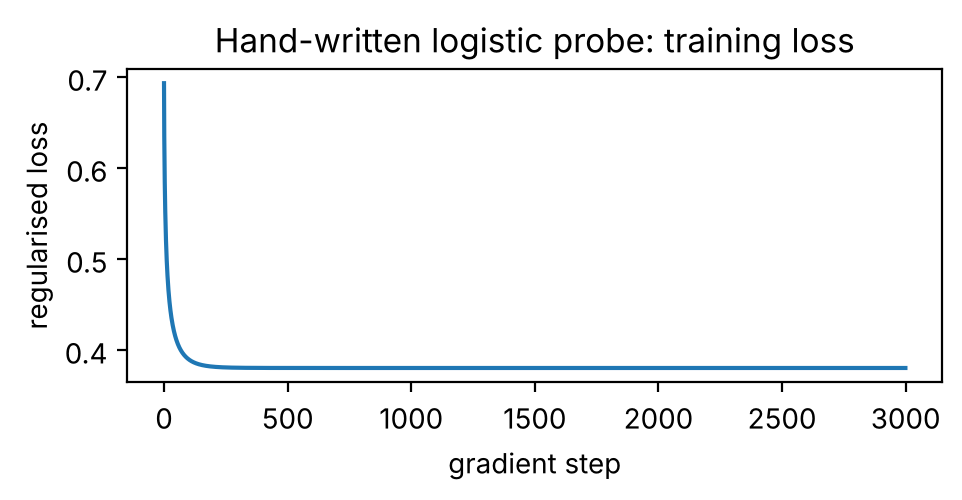

In [18]:
layer0 = N_LAYERS // 2
X = acts["mean"][:, layer0]                       # [N, d] features: answer-span mean at one layer

hand = LogisticProbe(C=cfg.probe_C).fit(X[tr], y[tr])
skl = lr_probe(cfg.probe_C).fit(X[tr], y[tr])
w_skl = skl.pipeline[-1].coef_[0]
cos = hand.w @ w_skl / (np.linalg.norm(hand.w) * np.linalg.norm(w_skl))

print(f"layer {layer0}, mean pooling")
print(f"  hand-written GD : train AUROC {auroc(y[tr], hand.score(X[tr])):.3f} | val AUROC {auroc(y[va], hand.score(X[va])):.3f}")
print(f"  scikit-learn    : train AUROC {auroc(y[tr], skl.score(X[tr])):.3f} | val AUROC {auroc(y[va], skl.score(X[va])):.3f}")
print(f"  cosine(w_hand, w_sklearn) = {cos:.4f}")

fig, ax = plt.subplots(figsize=(5, 2.6))
ax.plot(hand.losses)
ax.set(xlabel="gradient step", ylabel="regularised loss", title="Hand-written logistic probe: training loss")
plt.tight_layout(); plt.show()

The two solvers land on the same direction (cosine close to 1). Note the gap between train and validation AUROC: that gap is overfitting, and it is why only held-out numbers count.

### 3.5 Where is the information? Layer sweep

Fit the same probe at every layer for both poolings, score on **validation**.

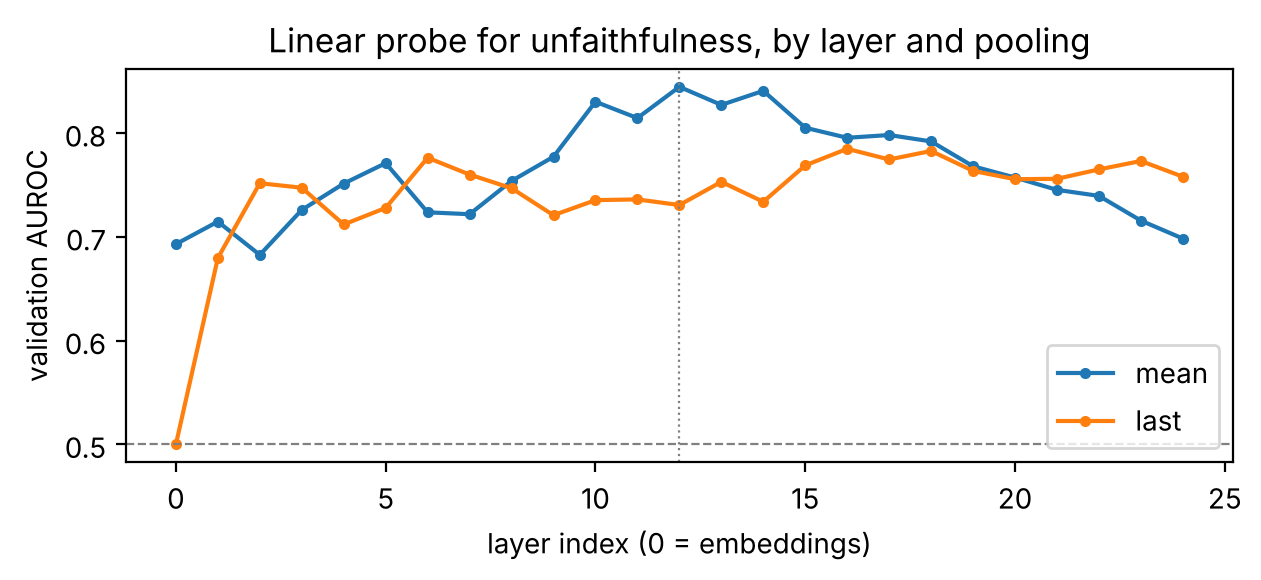

chosen on validation: pooling = mean, layer = 12, val AUROC = 0.844


In [19]:
sweep = layer_sweep(acts, y, splits, lambda: lr_probe(cfg.probe_C))
POOLING, LAYER = best_setting(sweep)

ax = sweep.plot(figsize=(6.5, 3), marker="o", ms=3)
ax.axhline(0.5, color="grey", lw=0.8, ls="--")
ax.axvline(LAYER, color="grey", lw=0.8, ls=":")
ax.set(xlabel="layer index (0 = embeddings)", ylabel="validation AUROC",
       title="Linear probe for unfaithfulness, by layer and pooling")
plt.tight_layout(); plt.show()
print(f"chosen on validation: pooling = {POOLING}, layer = {LAYER}, val AUROC = {sweep.loc[LAYER, POOLING]:.3f}")

How to read this plot:

- Layer 0 is the token embeddings before any attention. A probe there can only use *which words are in the answer*, not how they relate to the passage. Any score above 0.5 at layer 0 is a warning sign about lexical shortcuts.
- The rise over the early and middle layers is where the model has mixed passage information into the answer positions.
- The curve is noisy from layer to layer because validation has about 200 examples. Do not over-interpret which single layer wins; neighbouring layers are statistically tied.

### 3.6 Regularisation, and the one test-set evaluation

First, how much does $C$ matter at the chosen layer? Train AUROC shows how well the probe can fit; validation shows how well it generalises.

In [20]:
Xb = acts[POOLING][:, LAYER]                      # [N, d] features at the chosen setting
c_grid = [1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0]
rows = []
for C in c_grid:
    p = lr_probe(C).fit(Xb[tr], y[tr])
    rows.append({"C": C, "train AUROC": auroc(y[tr], p.score(Xb[tr])), "val AUROC": auroc(y[va], p.score(Xb[va]))})
c_table = pd.DataFrame(rows).set_index("C")
BEST_C = float(c_table["val AUROC"].idxmax())
print(c_table)
print("C chosen on validation:", BEST_C)

           train AUROC  val AUROC
C                                
1.000e-04        0.794      0.681
1.000e-03        0.904      0.808
1.000e-02        0.981      0.844
1.000e-01        1.000      0.839
1.000e+00        1.000      0.824
1.000e+01        1.000      0.823
C chosen on validation: 0.01


                               AUROC  CI low  CI high  TPR@5%FPR    n
name                                                                 
linear probe (mean, layer 12)   0.82   0.761    0.877      0.405  191


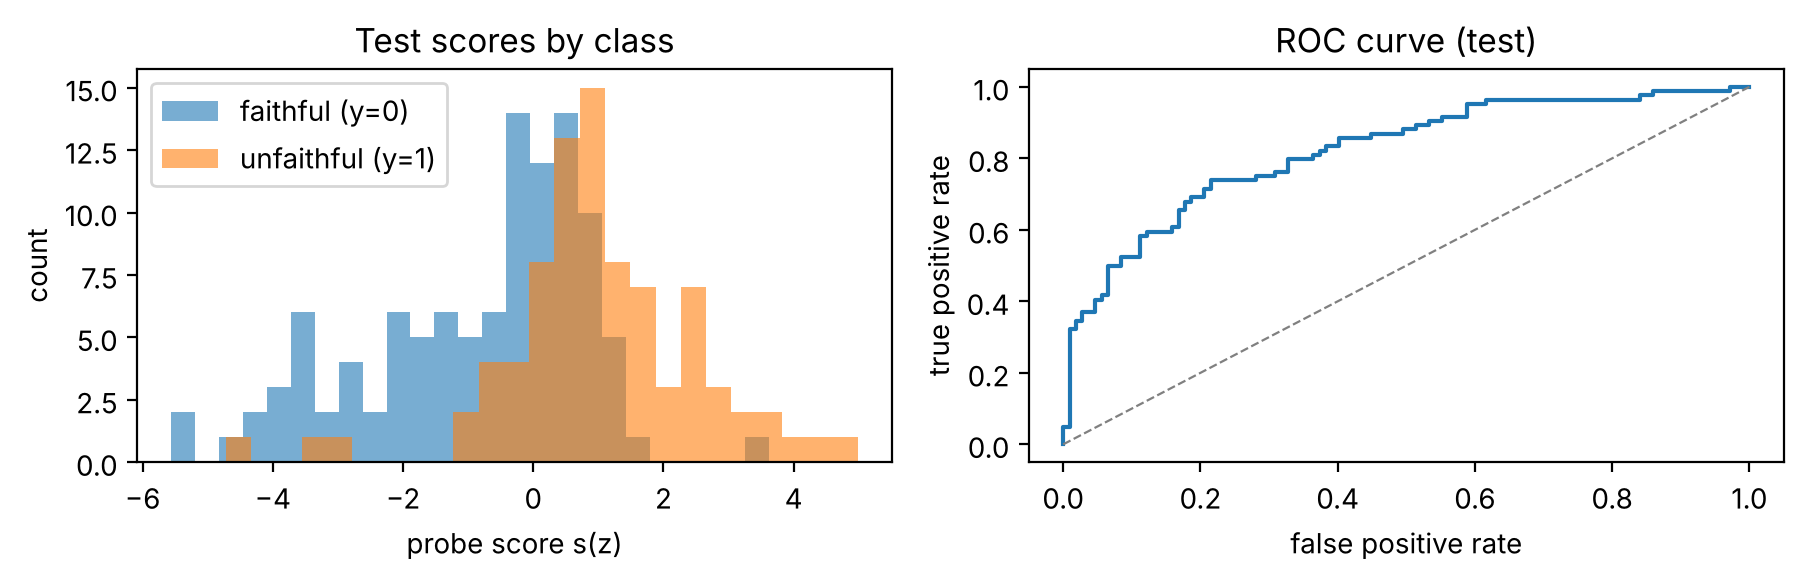

In [21]:
# Final probe: settings were chosen on validation, so the test set is touched exactly once, here.
probe = lr_probe(BEST_C).fit(Xb[tr], y[tr])
s_test = probe.score(Xb[te])
main_result = report(y[te], s_test, f"linear probe ({POOLING}, layer {LAYER})")
print(pd.DataFrame([main_result]).set_index("name"))

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].hist(s_test[y[te] == 0], bins=25, alpha=0.6, label="faithful (y=0)")
axes[0].hist(s_test[y[te] == 1], bins=25, alpha=0.6, label="unfaithful (y=1)")
axes[0].set(xlabel="probe score s(z)", ylabel="count", title="Test scores by class"); axes[0].legend()
fpr, tpr, _ = roc_curve(y[te], s_test)
axes[1].plot(fpr, tpr); axes[1].plot([0, 1], [0, 1], color="grey", ls="--", lw=0.8)
axes[1].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC curve (test)")
plt.tight_layout(); plt.show()

### 3.7 Is it measuring faithfulness? Baselines and controls

A single AUROC says nothing until you know what trivial methods score. Each row below isolates one alternative explanation for the probe's performance.

| Baseline | Sees | If it scores close to the probe, then... |
|---|---|---|
| Answer length | number of answer tokens | the labels leak through length |
| TF-IDF, answer only | which words are in the answer | the labels leak through answer wording |
| Novel-word rate | share of answer words absent from the passage | simple lexical overlap already solves the task |
| Zero-shot verdict | the model's own `No` minus `Yes` logit | the probe adds nothing over just asking the model |
| **Closed-book probe** | same probe, same layer, but the model never saw the passage | the probe is reading the answer's style, not its grounding |

The closed-book probe is the most important control. Faithfulness is defined relative to the passage, so a representation built *without* the passage cannot encode it. Whatever that probe achieves is shortcut signal, by construction.

In [22]:
def fit_and_score(make_probe, X, y, tr, te):
    """Fit on train rows of X, return scores on test rows."""
    return make_probe().fit(X[tr], y[tr]).score(X[te])


WORD = re.compile(r"[a-z0-9]+")


def novel_word_rate(passage: str, answer: str) -> float:
    """Share of the answer's words that never occur in the passage. No model, no training."""
    p_words = set(WORD.findall(passage.lower()))
    a_words = WORD.findall(str(answer).lower())
    return sum(w not in p_words for w in a_words) / max(len(a_words), 1)


# Closed-book control: same rows, same order, passage removed. Short inputs, so this is quick.
examples_cb = [row_to_example(r, with_passage=False) for r in data.itertuples()]
acts_cb = cached_extract("faithfulness_closed_book", examples_cb, model, tok, device, TOKEN_LAYER)

answers = data.answer.astype(str).to_numpy()
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2).fit(answers[tr])
X_tfidf = tfidf.transform(answers)
X_len = np.log1p(acts["n_span"]).reshape(-1, 1)

baseline_scores = {
    "answer length": fit_and_score(lambda: lr_probe(1.0), X_len, y, tr, te),
    "TF-IDF, answer only": LogisticRegression(C=1.0, max_iter=2000).fit(X_tfidf[tr], y[tr]).decision_function(X_tfidf[te]),
    "novel-word rate": np.array([novel_word_rate(p, a) for p, a in zip(data.passage, data.answer)])[te],
    "zero-shot verdict (No - Yes logit)": (acts["watch"][:, 1] - acts["watch"][:, 0])[te],
    f"closed-book probe (mean, layer {LAYER})": fit_and_score(lambda: lr_probe(BEST_C), acts_cb["mean"][:, LAYER], y, tr, te),
    f"linear probe ({POOLING}, layer {LAYER})": s_test,
}
baseline_table = pd.DataFrame([report(y[te], s, name) for name, s in baseline_scores.items()]).set_index("name")
baseline_table

,AUROC,CI low,CI high,TPR@5%FPR,n
name,,,,,
answer length,0.493,0.408,0.576,0.107,191
"TF-IDF, answer only",0.562,0.483,0.643,0.083,191
novel-word rate,0.566,0.484,0.653,0.071,191
zero-shot verdict (No - Yes logit),0.489,0.409,0.574,0.048,191
"closed-book probe (mean, layer 12)",0.783,0.718,0.842,0.357,191
"linear probe (mean, layer 12)",0.820,0.761,0.877,0.405,191


Pooled numbers hide a lot. Break the same comparison down by source dataset (test rows only, so each cell has about 40 examples and wide error bars).

In [23]:
def per_group_auroc(scores_by_name, y_eval, groups_eval):
    rows = {}
    for name, s in scores_by_name.items():
        rows[name] = {g: auroc(y_eval[groups_eval == g], s[groups_eval == g]) for g in np.unique(groups_eval)}
    return pd.DataFrame(rows).T


per_source = per_group_auroc(baseline_scores, y[te], groups[te])
per_source["pooled"] = baseline_table["AUROC"]
per_source

,DROP,FinanceBench,RAGTruth,halueval,pubmedQA,pooled
answer length,0.476,0.405,0.693,0.885,0.326,0.493
"TF-IDF, answer only",0.471,0.448,0.487,0.880,0.741,0.562
novel-word rate,0.486,0.492,0.591,0.947,0.476,0.566
zero-shot verdict (No - Yes logit),0.399,0.345,0.348,0.782,0.682,0.489
"closed-book probe (mean, layer 12)",0.922,0.631,0.553,0.962,0.696,0.783
"linear probe (mean, layer 12)",0.927,0.651,0.767,0.992,0.673,0.820


**How to read the two tables (the numbers quoted are from my run with the default config; yours will differ in the second decimal):**

- **The headline number is mostly not faithfulness.** The probe scores 0.82 (95% interval 0.76 to 0.88). The closed-book probe, which never saw the passage, scores 0.78 (0.72 to 0.84). The intervals overlap. Most of what the probe reads is available from the question and answer alone, so it cannot be grounding.
- **The shortcuts are source-specific.** On HaluEval, answer length alone reaches 0.89, novel-word rate 0.95 and the closed-book probe 0.96: the hallucinated answers there are longer and worded differently. On DROP the closed-book probe reaches 0.92, so the perturbed answers are recognisable by form. The cheap baselines look harmless when pooled (about 0.5) only because the shortcut points in different directions in different sources: longer means unfaithful in HaluEval and the opposite in pubmedQA (0.33).
- **RAGTruth is where the passage matters.** It is the only source of real model outputs with human labels. Closed-book: 0.55, close to chance. With the passage: 0.77. That gap of about 0.2 is the part of this experiment that looks like a faithfulness signal. It rests on about 40 test rows, so treat it as a lead, not a result.
- **The model's activations know more than its answer says.** Asking this 0.5B model for a Yes/No verdict is at chance (0.49), yet a linear readout of its middle layer separates RAGTruth answers. Grounding Probes report the same pattern with larger observers: the probe beat the same model's own verdict by a wide margin.
- **Layer 0 already told us.** In Section 3.5 the mean-pooled probe scores about 0.69 at the embedding layer, before the model has done any computation. That was the lexical shortcut showing up early.

The lesson for your own experiments: report the probe *minus* its strongest passage-free control, per source, not a pooled AUROC.

### 3.8 Why train accuracy is meaningless: fitting random labels

Shuffle the training labels so they carry no information, then fit a weakly regularised probe. With $d > N$ it still separates the training set.

In [24]:
rng = np.random.default_rng(cfg.seed)
y_shuffled = rng.permutation(y[tr])
memoriser = lr_probe(100.0).fit(Xb[tr], y_shuffled)          # C = 100: almost no regularisation

print(f"d = {Xb.shape[1]}, N_train = {len(tr)}")
print(f"random labels | train accuracy: {((memoriser.score(Xb[tr]) > 0) == y_shuffled).mean():.3f}")
print(f"random labels | test AUROC vs real labels: {auroc(y[te], memoriser.score(Xb[te])):.3f}")

d = 896, N_train = 557
random labels | train accuracy: 1.000
random labels | test AUROC vs real labels: 0.461


The probe fits pure noise on the training set and is at chance on held-out data. This is point 1 and point 3 of Section 1.7 in one experiment: a probe has enough capacity to memorise, so only held-out performance, compared against controls, is evidence about the representation. Hewitt and Liang (2019) turn this idea into a metric, *selectivity* (accuracy on the real task minus accuracy on a control task with random but consistent labels), originally for word-level probes.

### 3.9 Does it transfer? Leave one source out

In production the inputs never match the training distribution. Simulate it: train on all sources except one, test on the held-out source's test rows. Compare with the in-distribution probe on the same rows.

In [25]:
rows = []
for held_out in np.unique(groups):
    tr_other = tr[groups[tr] != held_out]                    # train rows from the other sources
    te_held = te[groups[te] == held_out]                     # test rows from the held-out source
    s_loso = fit_and_score(lambda: lr_probe(BEST_C), Xb, y, tr_other, te_held)
    s_in = probe.score(Xb[te_held])                          # probe trained on all sources
    rows.append({"held-out source": held_out, "n test": len(te_held),
                 "AUROC trained on all sources": auroc(y[te_held], s_in),
                 "AUROC source never seen": auroc(y[te_held], s_loso)})
loso_table = pd.DataFrame(rows).set_index("held-out source")
loso_table

,n test,AUROC trained on all sources,AUROC source never seen
held-out source,,,
DROP,40,0.927,0.495
FinanceBench,32,0.651,0.603
RAGTruth,39,0.767,0.537
halueval,40,0.992,0.682
pubmedQA,40,0.673,0.351


In my run the probe collapses on every source it was not trained on: DROP 0.93 to 0.50, RAGTruth 0.77 to 0.54, HaluEval 0.99 to 0.68, pubmedQA 0.67 to 0.35, FinanceBench 0.65 to 0.60. A score below 0.5 means the direction learned on the other sources points the *wrong way* on this one.

This is the same conclusion as Section 3.7 from a different angle. With a few hundred training rows from five differently constructed sources, the probe learned each source's tell rather than one shared notion of "unsupported by the passage". Published work sees milder versions of the same thing: Orgad et al. (2025) find truthfulness probes do not transfer across datasets, and Kramár et al. (2026) find probes fail under production distribution shift unless trained on diverse data. Things that should help, in rough order: train on real model outputs only (the full RAGTruth training split has about 15k responses), use a larger observer, and add many more sources.

### 3.10 Looking inside one example

Mean pooling followed by a linear probe has a useful property. Because both steps are linear,

$$
s(z) = w^\top \Big(\frac{1}{|S|}\sum_{t \in S} \tilde h_t\Big) + b = \frac{1}{|S|}\sum_{t \in S} \underbrace{\big(w^\top \tilde h_t + b\big)}_{\text{token score } s_t},
$$

so the example's score is exactly the average of per-token scores. We can colour each answer token by $s_t$ to see which tokens push the probe towards "unfaithful" (red) or "faithful" (blue). This uses a mean-pooling probe at `TOKEN_LAYER`, the layer whose per-token activations we kept.

In [26]:
token_probe_lr = lr_probe(BEST_C).fit(acts["mean"][tr, TOKEN_LAYER], y[tr])
scaler, clf = token_probe_lr.pipeline[0], token_probe_lr.pipeline[-1]


def token_scores(i: int) -> np.ndarray:
    """Per-token probe scores s_t for example i. Shape [T_span]."""
    H = acts["tokens"][i].astype(np.float32)                 # [T_span, d]
    return scaler.transform(H) @ clf.coef_[0] + clf.intercept_[0]


def show_token_scores(i: int):
    from IPython.display import HTML, display
    enc, span = tokenize_with_span(tok, examples[i])
    pieces = [tok.decode([t]) for t in enc["input_ids"][0][span].tolist()]
    s = token_scores(i)
    scale = np.abs(s).max() + 1e-6
    spans = []
    for piece, v in zip(pieces, s):
        colour = f"rgba(220,50,50,{abs(v) / scale:.2f})" if v > 0 else f"rgba(50,90,220,{abs(v) / scale:.2f})"
        spans.append(f"<span style='background:{colour}'>{html.escape(piece)}</span>")
    header = (f"<b>example {i}</b> | source {examples[i].group} | label {'unfaithful' if y[i] else 'faithful'}"
              f" | mean token score {s.mean():+.2f} (equals the sequence score)")
    display(HTML(header + "<br><div style='line-height:1.8'>" + "".join(spans) + "</div>"))


# One unfaithful and one faithful test example with a multi-sentence answer.
long_test = [i for i in te if acts["n_span"][i] >= 40]
for label in (1, 0):
    show_token_scores(next(i for i in long_test if y[i] == label))

### 3.11 Is one token enough? The signal along the answer

A natural worry: the model's state changes at every token it reads or writes, and its attention can move from the passage to its own text as an answer goes on. So is a single position a fair summary?

**Three positions, three different questions.**

| Position | What it has read | What a probe there can tell you |
|---|---|---|
| Last *input* token (`pre`: the token before the answer) | passage, question | Whether this prompt is *risky*, before any answer exists. Nothing about a particular answer. |
| Each *answer* token $t$ | passage, question, answer up to $t$ | Whether the answer *so far* looks unsupported. Changes token by token. |
| Last token after the suffix (`last`) | everything | A single summary, formed after reading the whole answer. |

In our observer setting the label depends on the answer, and a faithful and an unfaithful answer can follow the *same* passage and question. So a probe at the `pre` position should be near chance. If it is not, the dataset leaks the label through the passage or question. Compare all three positions by layer:

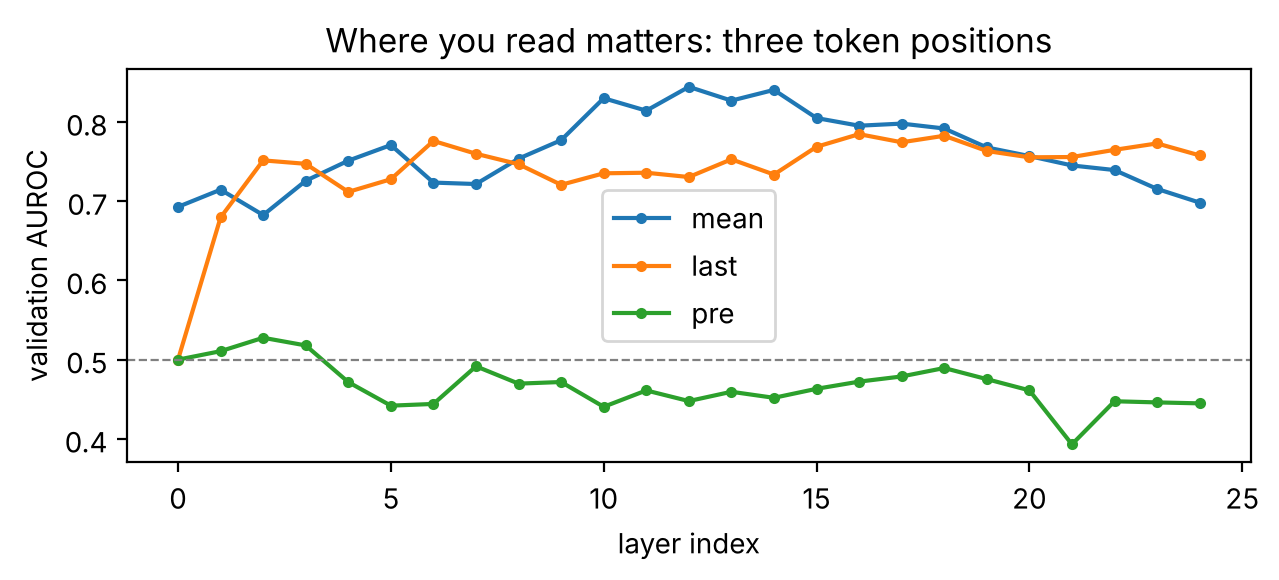

In [27]:
sweep_pre = layer_sweep(acts, y, splits, lambda: lr_probe(cfg.probe_C), poolings=("pre",))
ax = pd.concat([sweep, sweep_pre], axis=1).plot(figsize=(6.5, 3), marker="o", ms=3)
ax.axhline(0.5, color="grey", lw=0.8, ls="--")
ax.set(xlabel="layer index", ylabel="validation AUROC", title="Where you read matters: three token positions")
plt.tight_layout(); plt.show()

**The signal over time.** Now look *inside* the answer. Using the per-token scores $s_t$ from Section 3.10, average them by relative position in the answer (0 = first answer token, 1 = last), separately for faithful and unfaithful test answers. If the two curves separate only late, early tokens carry little evidence and a probe that reads one early position would miss it. The right panel asks the streaming question: if we stop after a fraction of the answer and use the mean score so far, how good is detection?

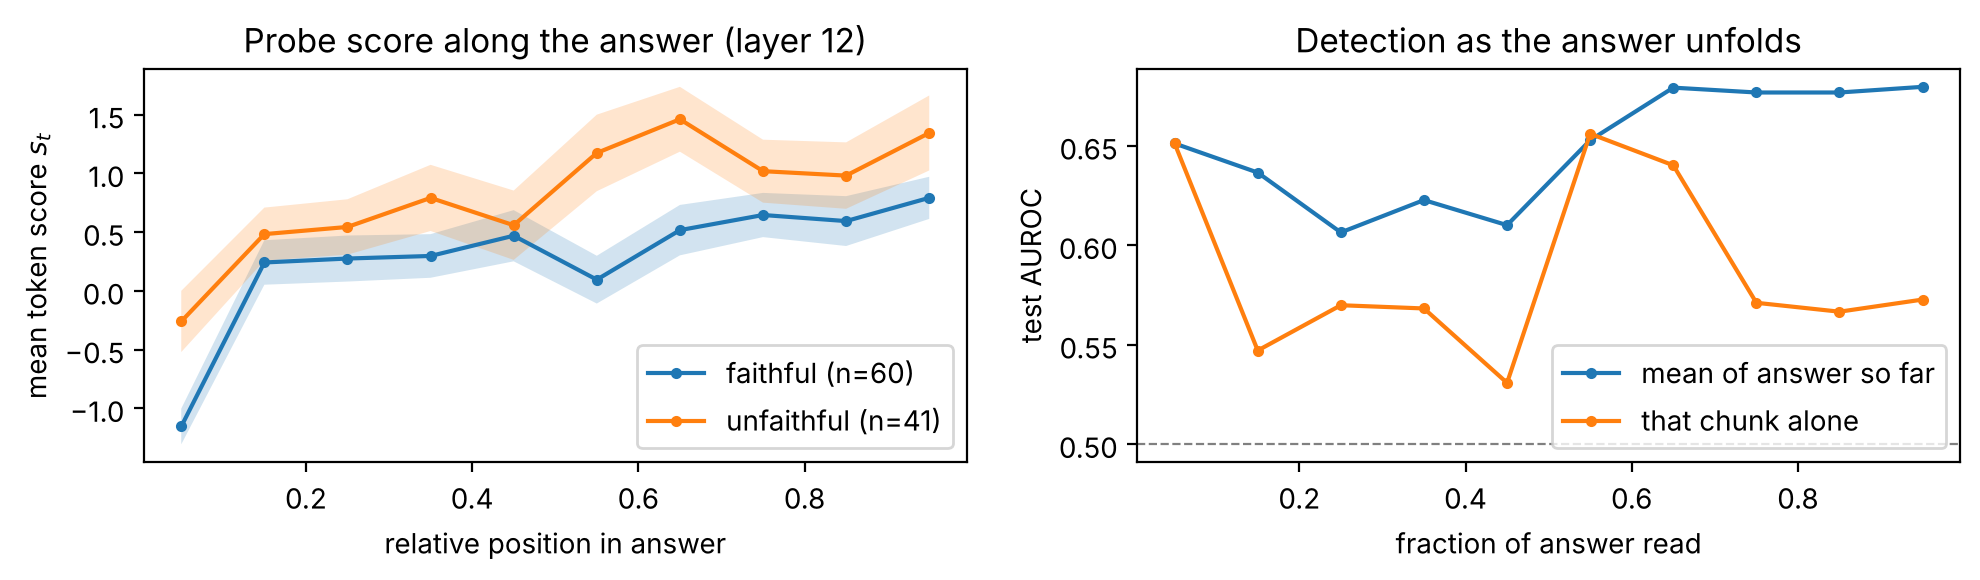

In [28]:
def binned_token_scores(idx, n_bins=10, min_len=20):
    # Rows: examples with at least min_len answer tokens. Columns: mean token score per relative-position bin.
    rows, keep = [], []
    for i in idx:
        s = token_scores(i)
        if len(s) < min_len:
            continue
        bins = np.array_split(s, n_bins)                 # n_bins consecutive chunks of the answer
        rows.append([b.mean() for b in bins])
        keep.append(i)
    return np.array(rows), np.array(keep)


B, kept = binned_token_scores(te)                        # B: [n_long, n_bins]
yk = y[kept]
pos = (np.arange(B.shape[1]) + 0.5) / B.shape[1]
running = np.cumsum(B, axis=1) / np.arange(1, B.shape[1] + 1)   # mean score of the answer so far

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for label, name in ((0, "faithful"), (1, "unfaithful")):
    m, se = B[yk == label].mean(0), B[yk == label].std(0) / np.sqrt((yk == label).sum())
    axes[0].plot(pos, m, marker="o", ms=3, label=f"{name} (n={(yk == label).sum()})")
    axes[0].fill_between(pos, m - se, m + se, alpha=0.2)
axes[0].set(xlabel="relative position in answer", ylabel="mean token score $s_t$",
            title=f"Probe score along the answer (layer {TOKEN_LAYER})"); axes[0].legend()
axes[1].plot(pos, [auroc(yk, running[:, j]) for j in range(B.shape[1])], marker="o", ms=3, label="mean of answer so far")
axes[1].plot(pos, [auroc(yk, B[:, j]) for j in range(B.shape[1])], marker="o", ms=3, label="that chunk alone")
axes[1].axhline(0.5, color="grey", lw=0.8, ls="--")
axes[1].set(xlabel="fraction of answer read", ylabel="test AUROC", title="Detection as the answer unfolds"); axes[1].legend()
plt.tight_layout(); plt.show()

**What I see in my run.**

- *Left plot of the previous cell.* The `pre` probe (last input token) sits between 0.45 and 0.5 at every layer: chance, as the argument above predicts. Reading the last input token tells you nothing about the answer here. `mean` over the answer is best in the middle layers (about 0.84 against 0.73 for `last` at layer 12); in the late layers `last` catches up.
- *Score along the answer* (101 test answers of 20 or more tokens, layer 12). Unfaithful answers score higher than faithful ones at every position, and the gap is widest in the second half. Both curves drift upwards, so the probe is also partly reading position.
- *Detection as the answer unfolds.* Any single tenth of the answer gives a noisy 0.53 to 0.66. The running mean climbs from about 0.65 after the first tenth to about 0.68 once 60% of the answer has been read. So the evidence is spread thinly over many tokens and no single position holds it; aggregation is what makes the probe work.

Caveats: this probe was trained on whole-answer labels, so its per-token scores are a by-product, not something it was trained to get right. And with about 100 long answers the curves are noisy.

**What the literature does about this**

- *Read every generated token, then aggregate.* This is what mean, attention and max pooling over the answer do (Section 4.3). Kramár et al. (2026) show the aggregation rule is the main thing that breaks on long inputs.
- *Score tokens or spans individually.* Obeso et al. (2025) train probes that flag unsupported entities as they are generated; RAGTruth has span-level labels for this.
- *Probe the attention drift directly.* Lookback Lens (Chuang et al., 2024) computes, for each generated token and each attention head, the share of attention going to the context versus to the model's own previous output, and classifies on that. It is the most direct test of "does attention to the passage fade as the answer goes on".
- *Choose the token deliberately.* Orgad et al. (2025) find the signal concentrates at the exact answer tokens, so the best single position is task dependent and is rarely the last input token.

One thing this notebook cannot show: in the **generator** setting (probing the model that writes the answer), the last input token is a legitimate and different probe. It predicts whether the model *is about to* hallucinate, which is useful for routing or abstaining, but it still cannot verify the answer that was produced.

## 4. Swaps: better methods than the baseline

The baseline was: residual stream, one layer, mean pooling over the answer, logistic regression. Every one of those four choices has published alternatives. Three are implemented below; the table in 4.4 lists the rest with citations.

### 4.1 Swap the classifier: difference of means and LDA

Section 1.5 in code. Same features, three linear directions:

- logistic regression: $w$ from minimising cross-entropy
- difference of means: $w = \mu_1 - \mu_0$
- LDA with shrinkage: $w = \hat\Sigma^{-1}(\mu_1 - \mu_0)$, where $\hat\Sigma$ is the pooled covariance pulled towards a multiple of the identity so it can be inverted when $d > N$

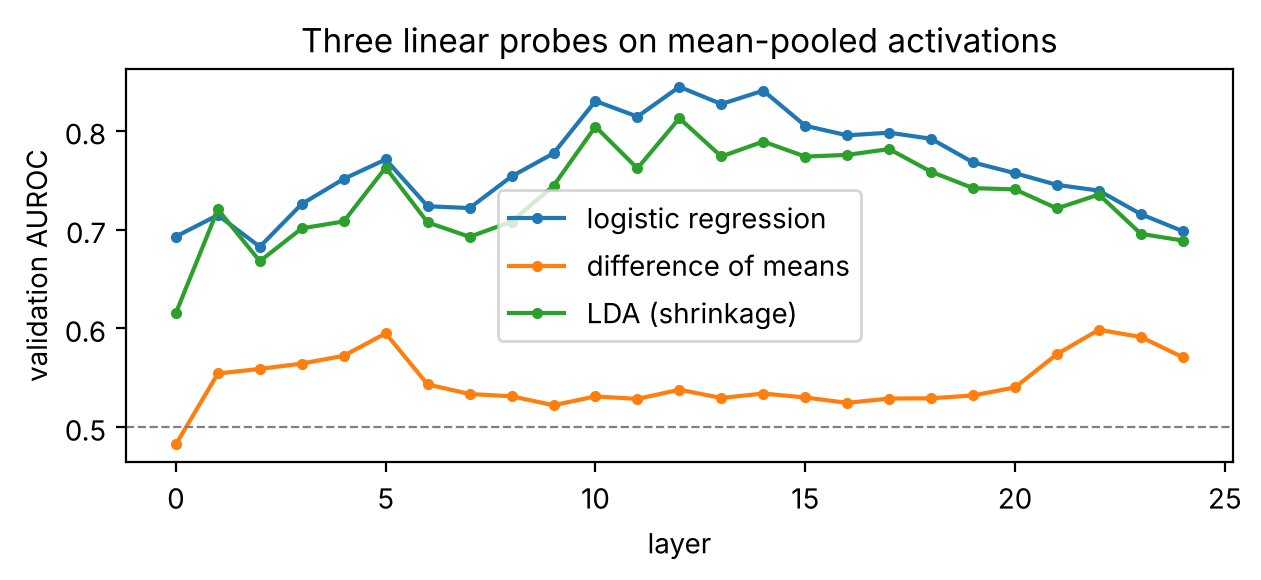

In [29]:
def lda_probe():
    return SklearnProbe(make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")))


Xp = acts[POOLING]                                           # [N, L+1, d]
linear_family = {"logistic regression": lambda: lr_probe(BEST_C), "difference of means": DiffMeansProbe, "LDA (shrinkage)": lda_probe}
curves = pd.DataFrame({name: [auroc(y[va], make().fit(Xp[tr, l], y[tr]).score(Xp[va, l])) for l in range(Xp.shape[1])]
                       for name, make in linear_family.items()}).rename_axis("layer")

ax = curves.plot(figsize=(6.5, 3), marker="o", ms=3)
ax.axhline(0.5, color="grey", lw=0.8, ls="--")
ax.set(ylabel="validation AUROC", title=f"Three linear probes on {POOLING}-pooled activations")
plt.tight_layout(); plt.show()

### 4.2 Swap the feature space: PCA before the probe

Grounding Probes (Rathmayr, Kovács and Recski, 2025) use: z-score, PCA to 512 components, logistic regression, on mean-pooled response tokens at a middle layer of the observer. PCA finds the $k$ orthogonal directions of largest variance in the training features and projects onto them,

$$
z' = U_k^\top (\tilde z - \bar z), \qquad U_k \in \mathbb{R}^{d \times k} \text{ = top-}k\text{ eigenvectors of the feature covariance},
$$

which cuts the number of probe parameters from $d$ to $k$. It is another way to regularise. With our small training set we sweep $k$.

In [30]:
def pca_lr_probe(k, C=1.0):
    return SklearnProbe(make_pipeline(StandardScaler(), PCA(n_components=k, random_state=0),
                                      StandardScaler(), LogisticRegression(C=C, max_iter=5000)))


k_grid = [k for k in (4, 16, 64, 128, 256, 512) if k < min(len(tr), Xb.shape[1])]
pca_table = pd.DataFrame([{"k": k, "val AUROC": auroc(y[va], pca_lr_probe(k).fit(Xb[tr], y[tr]).score(Xb[va]))}
                          for k in k_grid]).set_index("k")
BEST_K = int(pca_table["val AUROC"].idxmax())
print(pca_table.T)
print("k chosen on validation:", BEST_K)

k           4      16     64     128    256    512
val AUROC  0.51  0.729  0.792  0.841  0.778  0.674
k chosen on validation: 128


### 4.3 Swap the pooling: attention and max probes over tokens

Mean pooling weights every answer token equally. If one unsupported clause sits in a long, otherwise faithful answer, the mean dilutes it. Token-level probes fix this by scoring each token and learning how to aggregate.

Let $\tilde h_t$ be the standardised activation of answer token $t \in S$ at one layer. Each token gets a score $s_t = v^\top \tilde h_t$. The probes differ only in the aggregation:

$$
\begin{aligned}
\textbf{mean:}\quad & s = \frac{1}{|S|}\sum_{t\in S} s_t + b \\
\textbf{attention:}\quad & s = \sum_{t\in S} \alpha_t\, s_t + b, \qquad \alpha_t = \frac{\exp(q^\top \tilde h_t)}{\sum_{u \in S}\exp(q^\top \tilde h_u)} \\
\textbf{max:}\quad & s = \max_{t\in S}\, s_t + b
\end{aligned}
$$

The attention probe has a second learned vector $q$ that decides *where to look*; with $q = 0$ it reduces to the mean probe, which is how we initialise it. Kramár et al. (2026, Google DeepMind, "Building Production-Ready Probes for Gemini") find that softmax attention still dilutes on long inputs and propose **MultiMax**: several heads, each taking a hard max over tokens at inference. The `max` probe below is the single-head version of that idea.

These are trained with Adam on mini-batches. We keep the weights from the epoch with the best validation AUROC.

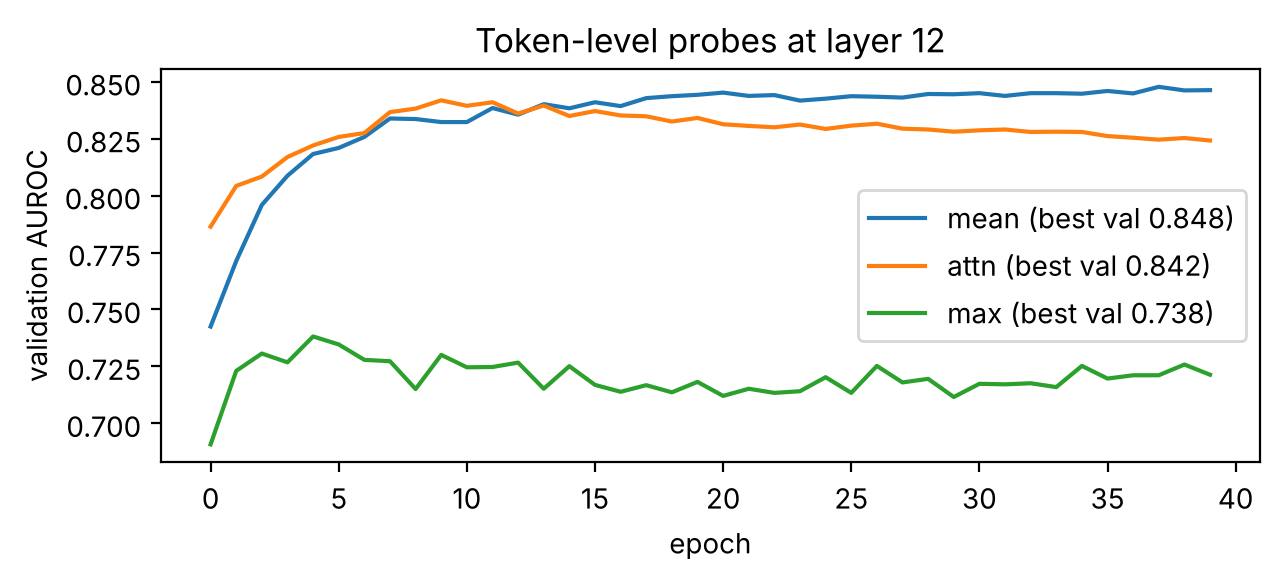

In [31]:
class TokenProbe(nn.Module):
    """Scores each token with v, then aggregates over the span with mean, attention or max."""

    def __init__(self, d: int, pool: str):
        super().__init__()
        assert pool in ("mean", "attn", "max")
        self.pool = pool
        self.v = nn.Linear(d, 1)                       # token scorer: s_t = v . h_t + b
        self.q = nn.Linear(d, 1, bias=False)           # attention query (used only when pool == "attn")
        nn.init.zeros_(self.q.weight)                  # q = 0 -> uniform attention -> starts as the mean probe
        nn.init.zeros_(self.v.weight)

    def forward(self, H, mask):
        """H: [B, T, d] padded token activations. mask: [B, T] True on real tokens. Returns [B] scores."""
        s = self.v(H).squeeze(-1)                                        # [B, T] token scores
        if self.pool == "max":
            return s.masked_fill(~mask, -1e9).max(dim=1).values
        if self.pool == "mean":
            alpha = mask.float() / mask.float().sum(dim=1, keepdim=True)  # [B, T] uniform weights
        else:
            alpha = torch.softmax(self.q(H).squeeze(-1).masked_fill(~mask, -1e9), dim=1)   # [B, T]
        return (alpha * s).sum(dim=1)


def token_stats(token_list, idx):
    """Per-dimension mean and std over all training tokens (for standardising)."""
    allt = np.concatenate([token_list[i] for i in idx]).astype(np.float32)   # [sum of T_i, d]
    return allt.mean(0), allt.std(0) + 1e-6


def collate(token_list, idx, mu, sd, max_len=256):
    """Pad a batch of variable-length [T_i, d] arrays into [B, T_max, d] plus a mask."""
    seqs = [(token_list[i][:max_len].astype(np.float32) - mu) / sd for i in idx]
    t_max = max(len(s) for s in seqs)
    H = np.zeros((len(seqs), t_max, seqs[0].shape[1]), dtype=np.float32)
    mask = np.zeros((len(seqs), t_max), dtype=bool)
    for j, s in enumerate(seqs):
        H[j, :len(s)], mask[j, :len(s)] = s, True
    return torch.from_numpy(H), torch.from_numpy(mask)


@torch.no_grad()
def token_probe_scores(net, token_list, idx, mu, sd, batch=64):
    net.eval()
    return np.concatenate([net(*collate(token_list, idx[i:i + batch], mu, sd)).numpy()
                           for i in range(0, len(idx), batch)])


def train_token_probe(token_list, y, tr, va, pool, epochs=40, lr=1e-3, weight_decay=1e-2, batch=32, seed=0):
    """Returns (best network, mu, sd, validation AUROC per epoch)."""
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    mu, sd = token_stats(token_list, tr)
    net = TokenProbe(token_list[0].shape[1], pool)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.BCEWithLogitsLoss()                    # cross-entropy of Section 1.4 on the pooled score
    best_auc, best_state, history = -1.0, None, []
    for _ in range(epochs):
        net.train()
        order = rng.permutation(tr)
        for i in range(0, len(order), batch):
            b = order[i:i + batch]
            H, mask = collate(token_list, b, mu, sd)
            loss = loss_fn(net(H, mask), torch.from_numpy(y[b]).float())
            opt.zero_grad(); loss.backward(); opt.step()
        val_auc = auroc(y[va], token_probe_scores(net, token_list, va, mu, sd))
        history.append(val_auc)
        if val_auc > best_auc:
            best_auc, best_state = val_auc, {k: v.clone() for k, v in net.state_dict().items()}
    net.load_state_dict(best_state)
    return net, mu, sd, history


token_results, token_test_scores = {}, {}
fig, ax = plt.subplots(figsize=(6.5, 3))
for pool in ("mean", "attn", "max"):
    net, mu_t, sd_t, hist = train_token_probe(acts["tokens"], y, tr, va, pool, seed=cfg.seed)
    token_results[pool] = max(hist)
    token_test_scores[pool] = token_probe_scores(net, acts["tokens"], te, mu_t, sd_t)
    ax.plot(hist, label=f"{pool} (best val {max(hist):.3f})")
ax.set(xlabel="epoch", ylabel="validation AUROC", title=f"Token-level probes at layer {TOKEN_LAYER}"); ax.legend()
plt.tight_layout(); plt.show()

### 4.4 All variants on the test set

Each variant's own hyperparameters were chosen on validation. The test set has about 200 rows, so check whether the confidence intervals overlap before declaring a winner.

In [32]:
variant_scores = {
    f"LR ({POOLING}, layer {LAYER})  [baseline]": s_test,
    f"difference of means ({POOLING}, layer {LAYER})": fit_and_score(DiffMeansProbe, Xb, y, tr, te),
    f"LDA shrinkage ({POOLING}, layer {LAYER})": fit_and_score(lda_probe, Xb, y, tr, te),
    f"PCA({BEST_K}) + LR ({POOLING}, layer {LAYER})": fit_and_score(lambda: pca_lr_probe(BEST_K), Xb, y, tr, te),
    f"token probe, mean pool (layer {TOKEN_LAYER})": token_test_scores["mean"],
    f"token probe, attention pool (layer {TOKEN_LAYER})": token_test_scores["attn"],
    f"token probe, max pool (layer {TOKEN_LAYER})": token_test_scores["max"],
}
variant_table = pd.DataFrame([report(y[te], s, name) for name, s in variant_scores.items()]).set_index("name")
variant_table

,AUROC,CI low,CI high,TPR@5%FPR,n
name,,,,,
"LR (mean, layer 12) [baseline]",0.820,0.761,0.877,0.405,191
"difference of means (mean, layer 12)",0.511,0.424,0.601,0.012,191
"LDA shrinkage (mean, layer 12)",0.744,0.678,0.813,0.238,191
"PCA(128) + LR (mean, layer 12)",0.819,0.760,0.876,0.464,191
"token probe, mean pool (layer 12)",0.823,0.764,0.878,0.500,191
"token probe, attention pool (layer 12)",0.825,0.769,0.881,0.357,191
"token probe, max pool (layer 12)",0.736,0.660,0.805,0.310,191


**Reading the table (my run).**

- Logistic regression (0.820), PCA + LR (0.819), the token-level mean probe (0.823) and the attention probe (0.825) are indistinguishable. Their intervals are about 0.06 wide on each side. On this data the choice among them does not matter; the data does.
- **Max pooling is worse (0.74).** A single-token max is a noisy statistic, and with a few hundred training sequences the probe cannot learn a token scorer clean enough for it. Kramár et al. use several heads and far more data.
- **Difference of means is at chance (0.51) when pooled, and LDA is in between (0.74).** The likely reason: our data mixes five sources whose activations differ from each other much more than faithful differs from unfaithful. Difference of means ignores the covariance, so those high-variance source directions dominate its score. LDA corrects for covariance and recovers part of the gap; logistic regression learns to ignore those directions. Check this yourself by fitting `DiffMeansProbe` inside a single source. The published successes of mass-mean probes are on clean, homogeneous statement datasets.
- A better classifier cannot fix what Section 3.7 found. All of these variants read the same shortcut-laden features.

### 4.5 Swaps from the literature that are not implemented here

Ordered by how directly they apply to RAG faithfulness. "Swap for" names the baseline component each one replaces.

| Method | Swap for | Idea in one line | Reference |
|---|---|---|---|
| Observer probe recipe | whole pipeline | Frozen observer reads context + question + response; mean-pool response tokens at a middle layer; z-score, PCA(512), logistic regression. Reports 0.88 to 0.89 AUROC on RAGTruth with 3B to 14B observers, well above asking the same model for a verdict. | Rathmayr, Kovács, Recski. *Grounding Probes: Generator-Independent Hallucination Detection from Observer Model Hidden States.* arXiv:2610.04642 (2025, preprint) |
| SAE feature probes (RAGLens) | feature space | Encode activations with a sparse autoencoder, select features by mutual information with the label, fit an additive model. Interpretable features that fire on unfaithful RAG output. | Xiong et al. *Toward Faithful Retrieval-Augmented Generation with Sparse Autoencoders.* ICLR 2026, arXiv:2512.08892 |
| ...with a caveat | feature space | Across 113 probing datasets, SAE-based probes did not consistently beat well-tuned baselines on raw activations. Treat SAEs as an interpretability gain, not an automatic accuracy gain. | Kantamneni et al. *Are Sparse Autoencoders Useful? A Case Study in Sparse Probing.* ICML 2025, arXiv:2502.16681 |
| Attention-ratio features (Lookback Lens) | what is probed | For every attention head, the ratio of attention on context tokens versus generated tokens; a linear classifier on those ratios. Uses attention maps only, transfers across tasks and models. | Chuang et al. *Lookback Lens.* EMNLP 2024, arXiv:2407.07071 |
| Context versus parametric scores (ReDeEP) | what is probed | Separately measure how much the residual stream draws on retrieved context (attention copying heads) and on parametric knowledge (FFN layers); hallucination when the second dominates. | Sun et al. *ReDeEP.* ICLR 2025, arXiv:2410.11414 |
| Context-knowledge signals (LUMINA) | what is probed | Context use as a distributional distance, internal-knowledge use by tracking how predicted tokens evolve across layers. Less hyperparameter tuning than ReDeEP. | Yeh, Li, Mallick. *LUMINA.* ICLR 2026, arXiv:2509.21875 |
| MultiMax and rolling-window attention probes | pooling | Hard max per head, or max over rolling attention windows, so a short harmful or unsupported span is not diluted in a long context. Also: cascade to an LLM judge when the probe is unsure. | Kramár et al. *Building Production-Ready Probes for Gemini.* arXiv:2601.11516 (2026) |
| Token- and span-level probes | label granularity | Train on span annotations so the probe flags *which* entities or tokens are unsupported, in real time during generation. RAGTruth ships span labels you can use for this. | Obeso et al. *Real-Time Detection of Hallucinated Entities in Long-Form Generation.* arXiv:2509.03531 (2025) |
| Exact-answer-token probing | token position | Truthfulness signal concentrates at the tokens of the exact answer; probing there beats last-token probing. Also shows probes generalise poorly across datasets. | Orgad et al. *LLMs Know More Than They Show.* ICLR 2025, arXiv:2410.02707 |
| Mass-mean probes | classifier | Difference of means (Section 4.1), with evidence that its direction is more causally implicated than the logistic regression direction. | Marks and Tegmark. *The Geometry of Truth.* COLM 2024, arXiv:2310.06824 |
| Semantic entropy probes | label source | No human labels: train the probe to predict semantic entropy computed from sampled generations. Useful when you control the generator. | Kossen et al. *Semantic Entropy Probes.* arXiv:2406.15927 (2024) |
| MLP probe (SAPLMA) | classifier | A small feed-forward network on one layer's activations. The original internal-state hallucination detector; more capacity, more overfitting risk, so the controls of Section 3 matter more. | Azaria and Mitchell. *The Internal State of an LLM Knows When It's Lying.* EMNLP Findings 2023, arXiv:2304.13734 |

Two papers about the *evaluation* rather than the method, both relevant to what Section 3.7 showed:

- Nomic's embedding analysis of HaluBench reports that a strong classifier can be built from the answer text alone: [Evaluating LLM hallucination benchmarks with embeddings](https://home.nomic.ai/blog/posts/evaluating-llm-hallucination-benchmarks-with-embeddings).
- *PARALLAX: Separating Genuine Hallucination Detection from Benchmark Construction Artifacts*, arXiv:2605.17028 (2026). I have only checked its title and related-work section, so read it before citing.

## 5. Adapt the pattern to your own task

To probe for another concept you write one function that returns a list of `ProbeExample`. Everything else is reused. Decide these five things first:

1. **Positive class.** What is $y = 1$? (Prompt injection present, PII present, answer unfaithful, ...)
2. **Span.** Which tokens have "seen" what is needed to know the label? Put everything before them in `context` and the span in `target`.
3. **Suffix.** Optional. Add one if you want a last-token readout at a decision point, or a zero-shot baseline in the same pass.
4. **`split_key`.** What must not be shared between train and test? (Same document, same user, same template.)
5. **Controls.** What trivial feature could predict the label, and what input would remove the real signal while keeping that feature? Build that as a second example list, as with the closed-book control.

```python
def build_my_examples() -> list[ProbeExample]:
    rows = ...  # load your data
    return [
        ProbeExample(
            context=...,       # text before the span
            target=...,        # span to pool over
            label=...,         # 1 = the thing to detect
            suffix="",         # optional
            group=...,         # for per-group reporting and leave-one-group-out
            split_key=...,     # leakage unit
        )
        for row in rows
    ]

study = run_probe_study("my_task", build_my_examples(), model, tok, device)
```

A complete second task in a few lines, to show nothing above was specific to faithfulness: movie-review sentiment (`y = 1` for a negative review).

                                   AUROC  CI low  CI high  TPR@5%FPR   n
name                                                                    
sentiment: last pooling, layer 22  0.969   0.929    0.995       0.71  60


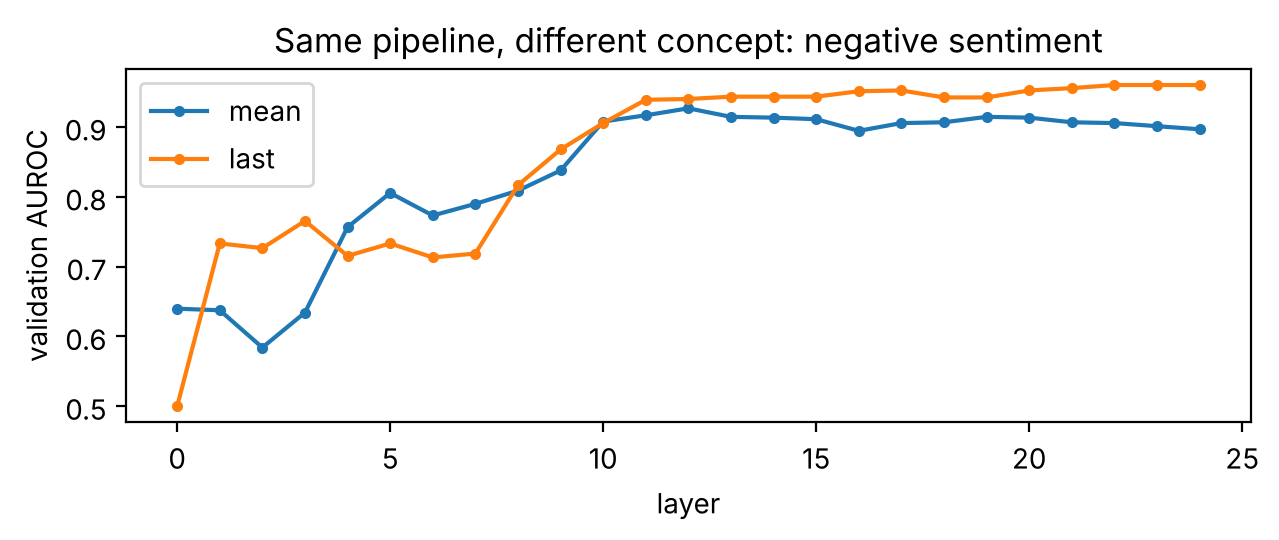

In [33]:
def build_sentiment_examples(n=300, seed=0) -> list[ProbeExample]:
    ds = load_dataset("cornell-movie-review-data/rotten_tomatoes", split="train").shuffle(seed=seed).select(range(n))
    return [ProbeExample(context="Review:", target=" " + r["text"].strip(), label=int(r["label"] == 0)) for r in ds]


study = run_probe_study("sentiment", build_sentiment_examples(), model, tok, device)
print(pd.DataFrame([study["result"]]).set_index("name"))
ax = study["sweep"].plot(figsize=(6.5, 2.8), marker="o", ms=3)
ax.set(ylabel="validation AUROC", title="Same pipeline, different concept: negative sentiment")
plt.tight_layout(); plt.show()

## 6. What you can and cannot conclude

**What a good held-out probe score supports**

- The label is linearly decodable from that layer's activations on this data distribution.
- Compared with the closed-book control, some of that decodable signal depends on the model having read the passage.

**What it does not support**

- That the model *uses* this direction when it writes or judges answers. That needs an intervention: add or remove the direction and see whether behaviour changes (steering, ablation, patching). Belinkov (2022) is the standard reference on this gap.
- That the probe detects "hallucination" in general. Section 3.9 measures how far it carries to an unseen source; Orgad et al. (2025) and Kramár et al. (2026) both report that probes degrade under distribution shift.
- That a higher number from a fancier probe means a better representation. More probe capacity means more of the work is done by the probe (Hewitt and Liang, 2019).

**Limits of this notebook in particular**

- One small observer model, one seed, one split, about 200 test rows. Treat differences of a few AUROC points as noise.
- Sequence-level labels. A long answer with one unsupported clause gets the same label as a fully invented one.
- The length filter removed long-context examples, which is the regime where published probes struggle most.
- Half of the sources use synthetic perturbations, and Section 3.7 shows at least one of them is solvable without the passage.

**Experiments to try next (each is a small edit)**

1. Change `cfg.model_name` to a larger observer and rerun. Does the closed-book gap grow?
2. Set `VERDICT_SUFFIX = ""` and compare last-token probes with and without the question.
3. Restrict the data to `RAGTruth` only (real model outputs) and raise `n_per_source_label`.
4. Concatenate several layers' features before the probe, or average scores from probes at different layers.
5. Implement the lookback ratio: rerun with `output_attentions=True` and, per head, divide attention mass on passage tokens by attention mass on answer tokens (Chuang et al., 2024).
6. Turn `max` pooling into MultiMax: several `v` vectors, hard max per head, sum the heads (Kramár et al., 2026).
7. Take the probe direction $w$ and add $\alpha w$ to the residual stream with a forward hook: the first step from probing to steering.

**Foundations reading list**

- Alain and Bengio (2016). *Understanding intermediate layers using linear classifier probes.* arXiv:1610.01644
- Hewitt and Liang (2019). *Designing and Interpreting Probes with Control Tasks.* EMNLP, arXiv:1909.03368
- Belinkov (2022). *Probing Classifiers: Promises, Shortcomings, and Advances.* Computational Linguistics, arXiv:2102.12452
- Niu et al. (2024). *RAGTruth: A Hallucination Corpus for Developing Trustworthy Retrieval-Augmented Language Models.* ACL, arXiv:2401.00396
- Ravi et al. (2024). *Lynx: An Open Source Hallucination Evaluation Model* (introduces HaluBench). arXiv:2407.08488